# Functional Preprocessing

**NX-421 — Neural Signals and Signal Processing**

In this notebook, we preprocess the language-task fMRI data from the Human Connectome Project (HCP).

We first correct for head motion using MCFLIRT and calculate framewise displacement to assess movement between consecutive functional volumes. We then apply Gaussian spatial smoothing and assess the alignment between the functional and anatomical images.

Following the methods introduced in Lab 3 and Lab4, we use FSL tools and Python to perform preprocessing and inspect the results.

The processed images and motion parameters will be used in the subsequent General Linear Model (GLM) analysis.

The notebook is designed for Neurodesk, with the dataset stored in `data/` and the repository root used as the working directory. All generated outputs are saved separately to preserve the original data.

## 0. Setup

First, we load FSL and the Python libraries. We use the same FSL version as in the labs. The paths below correspond to our project folder; `DATA_DIR` can be changed if the data are stored somewhere else.

In [1]:
import os
import sys
import shutil
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from nilearn import image, plotting

# Load FSL in Neurodesk, as in Labs 2 and 3.
import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')


# Keep the output extension consistent with the downstream notebooks.
os.environ['FSLOUTPUTTYPE'] = 'NIFTI_GZ'
if not os.environ.get('FSLDIR'):
    raise RuntimeError('FSLDIR is not set. Check that the Neurodesk FSL module loaded.')
for tool in ['mcflirt', 'fslmaths', 'flirt']:
    if shutil.which(tool) is None:
        raise RuntimeError(f'{tool} is unavailable. Check the Neurodesk FSL module.')

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| pandas:', pd.__version__, '| NiBabel:', nib.__version__)
fsl_version_path = Path(os.environ['FSLDIR']) / 'etc' / 'fslversion'
if fsl_version_path.is_file():
    print('FSL:', fsl_version_path.read_text().strip())

Python: 3.13.13
NumPy: 2.3.5 | pandas: 3.0.6 | NiBabel: 5.4.2
FSL: 6.0.7.18


In [2]:
PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / 'data'
FUNC_DATA_DIR = DATA_DIR / 'fMRI' / 'tfMRI_LANGUAGE_LR'
OUTPUT_DIR = PROJECT_ROOT / 'outputs' / 'functional'

raw_fmri_path = FUNC_DATA_DIR / 'tfMRI_LANGUAGE_LR.nii.gz'
# MCFLIRT takes an output basename, without .nii.gz.
moco_basename = OUTPUT_DIR / 'tfMRI_LANGUAGE_LR_mcf'
moco_fmri_path = OUTPUT_DIR / 'tfMRI_LANGUAGE_LR_mcf.nii.gz'
motion_par_path = OUTPUT_DIR / 'tfMRI_LANGUAGE_LR_mcf.par'
smoothed_fmri_path = OUTPUT_DIR / 'tfMRI_LANGUAGE_LR_mcf_smooth.nii.gz'

FD_THRESHOLD = 0.5  # mm, fixed high-motion screening threshold
FWHM_MM = 6.0       # same smoothing width as Lab 3

if not raw_fmri_path.is_file():
    raise FileNotFoundError(f'Input not found: {raw_fmri_path}. Check DATA_DIR and the working directory.')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Input:', raw_fmri_path)
print('Outputs:', OUTPUT_DIR)

description_path = DATA_DIR / 'dataset_description.md'
if description_path.is_file():
    print('Dataset description:\n', description_path.read_text())
else:
    print('dataset_description.md was not found under DATA_DIR; inspect the supplied description separately.')

Input: /data/Desktop/myfiles/NX421-MiniProject-1/data/fMRI/tfMRI_LANGUAGE_LR/tfMRI_LANGUAGE_LR.nii.gz
Outputs: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/functional
Dataset description:
 Single-subject MRI and fMRI recordings from the Language task (1 run per task)

More details on the task structure can be found at https://www.humanconnectome.org/hcp-protocols-ya-task-fmri




### 0.1 Looking at the input data

Before processing the images, we check their dimensions, voxel sizes and TR. The dataset description is also useful to find out which preprocessing steps have already been applied. If the supplied images have already been realigned, the motion parameters estimated here will only describe the remaining movement.

Like in Lab 3, we plot the mean intensity over time to look for unusual volumes, especially at the start of the run. Changes in these first volumes can come from magnetisation not yet reaching a steady state, rather than from head movement.

We keep all volumes so that the timing stays consistent with the events used for the GLM. Suspicious volumes can then be accounted for in that analysis.

Dimensions: (91, 109, 91, 316)
Voxel sizes: (np.float32(2.0), np.float32(2.0), np.float32(2.0))
Spatial/time units: ('mm', 'sec')
TR (header units): 0.7200000286102295
Orientation: ('L', 'A', 'S')
Affine:
 [[  -2.    0.    0.   90.]
 [   0.    2.    0. -126.]
 [   0.    0.    2.  -72.]
 [   0.    0.    0.    1.]]


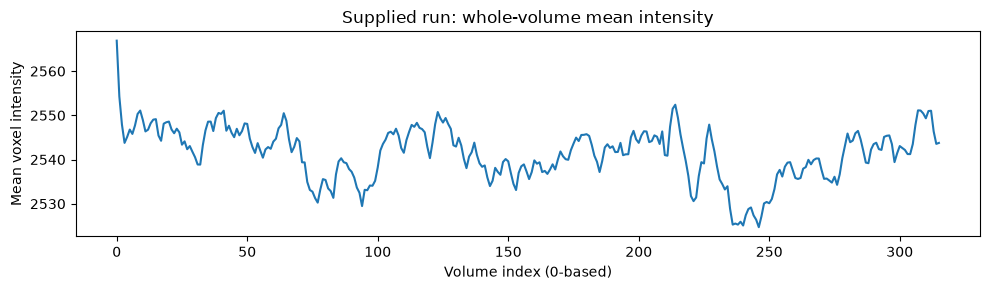

In [3]:
raw_img = nib.load(str(raw_fmri_path))
if len(raw_img.shape) != 4 or raw_img.shape[3] < 2:
    raise ValueError('Expected a 4D fMRI run with at least two volumes.')

n_volumes = raw_img.shape[3]
voxel_sizes = raw_img.header.get_zooms()[:3]
tr_header = float(raw_img.header.get_zooms()[3])
print('Dimensions:', raw_img.shape)
print('Voxel sizes:', voxel_sizes)
print('Spatial/time units:', raw_img.header.get_xyzt_units())
print('TR (header units):', tr_header)
print('Orientation:', nib.aff2axcodes(raw_img.affine))
print('Affine:\n', raw_img.affine)

# Same whole-volume mean as Lab 3; load one volume at a time to limit memory use.
mean_intensity = np.array([
    np.asarray(raw_img.dataobj[..., v], dtype=np.float32).mean()
    for v in range(n_volumes)
])
if not np.all(np.isfinite(mean_intensity)):
    raise ValueError('Non-finite values found in the input mean-intensity trace.')

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(np.arange(n_volumes), mean_intensity)
ax.set(xlabel='Volume index (0-based)', ylabel='Mean voxel intensity',
       title='Supplied run: whole-volume mean intensity')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'mean_intensity.png', dpi=200)
plt.show()

**Results.** The functional run contains 316 volumes (91 × 109 × 91 voxels, 2 mm isotropic, TR = 0.72 s). The first volume has a clearly higher mean intensity than the rest of the run (about 1 % above the average level), and the second volume is still slightly elevated (about 0.5 %). From the third volume onwards, the signal fluctuates slowly within about ±0.5 % around a stable level, reflecting slow drifts and global signal fluctuations rather than an initial transient.

This pattern is typical of non-steady-state magnetisation at the start of the acquisition. Since the effect is small and limited to the first two volumes, we keep all volumes to preserve the timing of the task events, and we account for volumes 0 and 1 in the GLM with spike (censoring) regressors.

We also note that the voxels outside the brain are already set to zero: the supplied run has been brain-masked, which indicates that it was distributed after the HCP minimal preprocessing pipeline.

## 1. Motion Correction (2a)

### 1.1 MCFLIRT

When the subject moves, a voxel may no longer correspond to the same part of the brain across the run. To reduce this problem, we use MCFLIRT, to align the volumes to a common reference.

We keep the default reference, which is the middle volume, and use six degrees of freedom: three rotations and three translations. This allows rigid-body movement without changing the shape or size of the brain.

The `.par` file stores the motion parameters for each volume, with rotations in radians and translations in millimetres. We also save the transformation matrices using `mats=True`.

In [4]:
subprocess.run(['mcflirt', '-in', str(raw_fmri_path), '-out', str(moco_basename),
                '-plots', '-report', '-dof', '6', '-mats'],
               check=True, capture_output=True)

for path in [moco_fmri_path, motion_par_path]:
    if not path.is_file():
        raise FileNotFoundError(f'MCFLIRT output missing: {path}')

moco_img = nib.load(str(moco_fmri_path))
assert moco_img.shape == raw_img.shape, 'MCFLIRT changed the image dimensions.'
assert np.allclose(moco_img.affine, raw_img.affine), 'Unexpected change in the spatial grid.'
assert np.allclose(moco_img.header.get_zooms(), raw_img.header.get_zooms()), 'Voxel sizes or TR changed.'

matrix_dir = Path(str(moco_basename) + '.mat')
matrix_paths = sorted(matrix_dir.glob('MAT_*'))
assert len(matrix_paths) == n_volumes, 'Expected one MCFLIRT matrix per volume.'
for path in matrix_paths:
    matrix = np.loadtxt(path)
    assert matrix.shape == (4, 4) and np.all(np.isfinite(matrix)), f'Invalid matrix: {path}'
print('MCFLIRT outputs and geometry checked.')

MCFLIRT outputs and geometry checked.


### 1.2 Motion parameters

We load the `.par` file with the function from Lab 3. The only small change is the whitespace separator, so that it also works if the spacing between columns varies. We then plot rotations and translations separately because they have different units.

In [5]:
def load_mot_params_fsl_6_dof(path):
    return pd.read_csv(path, sep=r'\s+', header=None,
            engine='python', names=['Rotation x', 'Rotation y', 'Rotation z',
                                    'Translation x', 'Translation y', 'Translation z'])

mot_params = load_mot_params_fsl_6_dof(motion_par_path)
assert mot_params.shape == (n_volumes, 6), 'Motion parameters must have one row per volume and six columns.'
assert np.all(np.isfinite(mot_params.to_numpy())), 'Invalid motion parameters.'
mot_params.head()

,Rotation x,Rotation y,Rotation z,Translation x,Translation y,Translation z
0,-0.000080,0.000388,-0.000901,0.020150,-0.043444,0.055774
1,0.000163,0.000492,-0.000059,0.030005,-0.038251,0.059965
2,-0.000031,0.000411,-0.001100,0.012959,-0.025233,0.051918
3,0.000297,-0.000309,-0.000091,-0.042305,-0.029215,0.039045
4,0.000089,-0.000224,-0.000001,-0.034639,-0.014459,0.047900


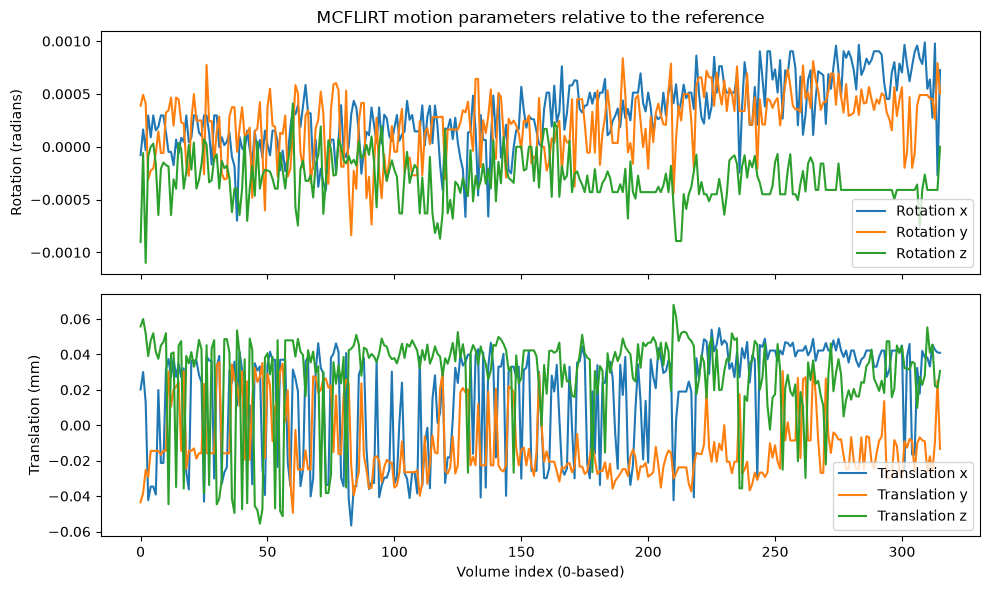

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for name in ['Rotation x', 'Rotation y', 'Rotation z']:
    axes[0].plot(mot_params.index, mot_params[name], label=name)
for name in ['Translation x', 'Translation y', 'Translation z']:
    axes[1].plot(mot_params.index, mot_params[name], label=name)
axes[0].set(ylabel='Rotation (radians)', title='MCFLIRT motion parameters relative to the reference')
axes[1].set(xlabel='Volume index (0-based)', ylabel='Translation (mm)')
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'motion_parameters.png', dpi=200)
plt.show()

**Results.** The motion parameters estimated by MCFLIRT indicate limited head movement throughout the functional run.

Rotations remain approximately within ±0.001 radians (about 0.06°), while translations are generally within ±0.07 mm. These displacements are small compared with the 2 mm isotropic voxel resolution.

The curves show small fluctuations between successive volumes, together with a gradual change in some parameters over time, particularly the x-axis rotation.

Overall, the estimated movement appears limited, although small head movements can still influence the fMRI signal. The six motion parameters will therefore be considered as nuisance regressors in the subsequent GLM analysis.

These very small values are expected, because the HCP minimal preprocessing pipeline already includes motion correction: MCFLIRT here only estimates the **residual** motion left in the supplied run, part of which is likely estimation noise rather than real head movement.

### 1.3 Framewise displacement

The motion parameters describe the position relative to the reference volume. To look at movement between consecutive volumes, we calculate framewise displacement (FD) with `compute_FD_power`.

The function adds the absolute differences in translation and rotation. Rotations are converted to distances using a sphere with a radius of 50 mm:

$$FD_t = |\Delta x_t| + |\Delta y_t| + |\Delta z_t| + 50(|\Delta\alpha_t| + |\Delta\beta_t| + |\Delta\gamma_t|).$$

There is no FD value for the first volume because it has no previous volume to compare with. We therefore get N - 1 values, starting at volume index 1 (indices start at 0).

We use two thresholds to identify motion outliers: a fixed threshold of 0.5 mm for screening larger movements, and a data-driven threshold based on the interquartile range (Q3 + 1.5 × IQR), following Lab 3.

These thresholds are used for quality control rather than automatic volume removal. The mean and maximum FD, together with the flagged volume indices, are reported below.

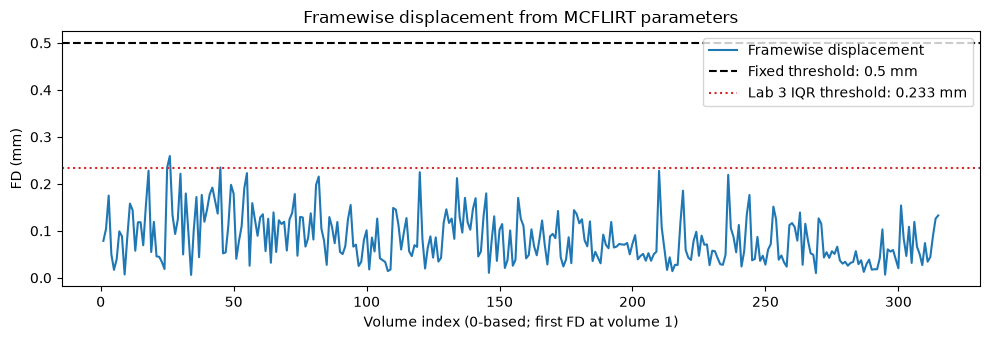

Mean FD: 0.0848 mm
Maximum FD: 0.2592 mm
Maximum FD at volume: 26
Transitions above 0.5 mm: 0/315
Lab 3 IQR threshold: 0.2334 mm
Transitions above IQR threshold: 3/315
IQR-flagged volume indices: [25, 26, 45]


In [7]:
# Compute Power-style framewise displacement from MCFLIRT parameters
def compute_FD_power(mot_params):
    framewise_diff = mot_params.diff().iloc[1:]

    # Convert rotations (radians) to displacement (mm)
    # using an approximate head radius of 50 mm
    rot_params = framewise_diff[
        ["Rotation x", "Rotation y", "Rotation z"]
    ]
    converted_rots = rot_params * 50

    trans_params = framewise_diff[
        ["Translation x", "Translation y", "Translation z"]
    ]

    fd = (
        converted_rots.abs().sum(axis=1)
        + trans_params.abs().sum(axis=1)
    )

    return fd


# Calculate FD for consecutive volumes
fd = compute_FD_power(mot_params).to_numpy()
fd_volume_indices = np.arange(1, n_volumes)

assert fd.shape == (n_volumes - 1,)
assert np.all(np.isfinite(fd))
assert np.all(fd >= 0)

# Fixed threshold
flagged_volumes = fd_volume_indices[fd > FD_THRESHOLD]

# Data-driven outlier threshold from Lab 3
q1, q3 = np.quantile(fd, [0.25, 0.75])
fd_iqr_threshold = q3 + 1.5 * (q3 - q1)
flagged_iqr = fd_volume_indices[fd > fd_iqr_threshold]

# Save FD values and quality-control flags
fd_df = pd.DataFrame({
    "volume_index": fd_volume_indices,
    "fd_mm": fd,
    "above_fixed_threshold": fd > FD_THRESHOLD,
    "above_iqr_threshold": fd > fd_iqr_threshold
})

fd_df.to_csv(
    OUTPUT_DIR / "framewise_displacement.csv",
    index=False
)

# Visualize FD with both thresholds
fig, ax = plt.subplots(figsize=(10, 3.5))

ax.plot(fd_volume_indices, fd, label="Framewise displacement")

ax.axhline(
    FD_THRESHOLD,
    color="black",
    linestyle="--",
    label=f"Fixed threshold: {FD_THRESHOLD} mm"
)

ax.axhline(
    fd_iqr_threshold,
    color="tab:red",
    linestyle=":",
    label=f"Lab 3 IQR threshold: {fd_iqr_threshold:.3f} mm"
)

ax.set(
    xlabel="Volume index (0-based; first FD at volume 1)",
    ylabel="FD (mm)",
    title="Framewise displacement from MCFLIRT parameters"
)

ax.legend()
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "framewise_displacement.png",
    dpi=200
)

plt.show()

# Print quantitative results
print(f"Mean FD: {fd.mean():.4f} mm")
print(f"Maximum FD: {fd.max():.4f} mm")
print(f"Maximum FD at volume: {fd_volume_indices[np.argmax(fd)]}")

print(
    f"Transitions above {FD_THRESHOLD} mm: "
    f"{len(flagged_volumes)}/{fd.size}"
)

print(
    f"Lab 3 IQR threshold: {fd_iqr_threshold:.4f} mm"
)

print(
    f"Transitions above IQR threshold: "
    f"{len(flagged_iqr)}/{fd.size}"
)

print("IQR-flagged volume indices:", flagged_iqr.tolist())

**Results.** The framewise displacement remained low throughout the run, with a mean FD of **0.0848 mm** and a maximum of **0.2592 mm** at volume 26. None of the 315 volume-to-volume transitions exceeded the fixed 0.5 mm threshold.

Using the data-driven outlier threshold from Lab 3 (Q3 + 1.5 × IQR = **0.2334 mm**), three transitions were flagged, corresponding to volumes **25, 26, and 45**. These correspond to two brief events (volumes 25–26 and volume 45) at the beginning of the run, rather than sustained periods of high motion; FD is overall slightly higher during the first ~60 volumes and lower afterwards.

Overall, the estimated movement was small relative to the 2 mm voxel size. No volumes were removed during preprocessing. Nevertheless, the motion parameters will be retained as potential nuisance regressors for the GLM, since even small movements may introduce signal fluctuations.

### 1.4 Checking the correction

We compare the original and corrected images at the volume with the highest FD, using the same slices and intensity scale. We can also open both runs in FSLeyes to go through the volumes and check whether the brain stays better aligned over time.

The FD calculated above describes the estimated movement in the input run; it does not measure how much movement remains after correction. As discussed in Lab 3, realignment cannot correct every signal change caused by motion. This is why the motion parameters are also useful as nuisance regressors in the GLM.

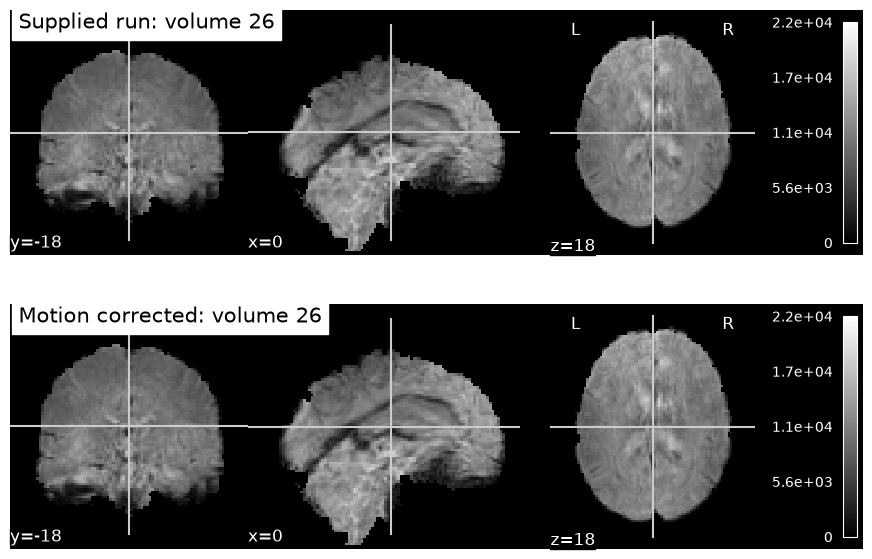

In [8]:
qc_volume_index = int(fd_volume_indices[np.argmax(fd)])
raw_volume = image.index_img(raw_img, qc_volume_index)
corrected_volume = image.index_img(moco_img, qc_volume_index)
raw_volume_data = raw_volume.get_fdata()
corrected_volume_data = corrected_volume.get_fdata()
assert np.all(np.isfinite(corrected_volume_data)), 'Non-finite corrected volume.'

# A common physical coordinate in both images, at the centre of the input grid.
centre_voxel = (np.array(raw_img.shape[:3]) - 1) / 2
cut_coords = tuple(nib.affines.apply_affine(raw_img.affine, centre_voxel))
vmin = min(raw_volume_data.min(), corrected_volume_data.min())
vmax = max(raw_volume_data.max(), corrected_volume_data.max())

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
for ax, volume, title in zip(axes, [raw_volume, corrected_volume],
                             ['Supplied run', 'Motion corrected']):
    plotting.plot_epi(volume, axes=ax, display_mode='ortho', cut_coords=cut_coords,
                      cmap='gray', vmin=vmin, vmax=vmax, colorbar=True,
                      title=f'{title}: volume {qc_volume_index}')
fig.savefig(OUTPUT_DIR / 'motion_correction_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

In [9]:
# Optional interactive QC, as in the labs. Set True on the VM to launch FSLeyes.
OPEN_FSLEYES = False
if OPEN_FSLEYES:
    subprocess.Popen(['fsleyes', str(raw_fmri_path), str(moco_fmri_path)])

**Results.** The supplied and motion-corrected functional images were compared at volume 26, which corresponds to the largest estimated framewise displacement (0.2592 mm).

The two images appear visually very similar, with no obvious differences in the anatomical structures. This is consistent with the small head movements estimated by MCFLIRT, which are substantially smaller than the 2 mm isotropic voxel resolution.

However, the absence of visible differences in a single volume does not demonstrate that motion correction was unnecessary or that temporal alignment improved. Small sub-voxel movements may still affect the fMRI signal.

Overall, MCFLIRT completed successfully and preserved all 316 functional volumes. The estimated motion parameters can also be used as nuisance regressors in the subsequent GLM analysis.

## 2. Gaussian Smoothing (2b)

### 2.1 Applying the filter

Gaussian smoothing averages nearby voxels, giving more weight to those closest to the centre of the kernel. As seen in Lab 3, this can reduce noise, but it also blurs small structures and fine activation patterns.

We use a FWHM of 6 mm, following the example in the lab. This gives a reasonable starting point for spatial averaging, although it is not a value optimised for this particular subject. The code also prints its size relative to the voxel dimensions.

FSL takes the Gaussian standard deviation in millimetres, so we first convert FWHM to sigma:

$$\sigma = \frac{FWHM}{2.3548}.$$

We apply this filter to the motion-corrected run with `fslmaths -s`. Smoothing is spatial only; we do not smooth across time.

In [10]:
sigma_mm = FWHM_MM / 2.3548
print(f'FWHM: {FWHM_MM:g} mm; sigma: {sigma_mm:.4f} mm')
print('FWHM / voxel size along each image axis:', FWHM_MM / np.array(voxel_sizes))

# Lab 3 smoothing command, with project paths and explicit failure checking.
subprocess.run([
    'fslmaths', str(moco_fmri_path), '-s', str(sigma_mm), str(smoothed_fmri_path)
], check=True)

if not smoothed_fmri_path.is_file():
    raise FileNotFoundError(f'Smoothing output missing: {smoothed_fmri_path}')
smoothed_img = nib.load(str(smoothed_fmri_path))
assert smoothed_img.shape == moco_img.shape, 'Smoothing changed the image dimensions.'
assert np.allclose(smoothed_img.affine, moco_img.affine), 'Smoothing changed the spatial grid.'
assert np.allclose(smoothed_img.header.get_zooms(), moco_img.header.get_zooms()), 'Voxel sizes or TR changed.'
print('Smoothed image geometry checked.')

FWHM: 6 mm; sigma: 2.5480 mm
FWHM / voxel size along each image axis: [3. 3. 3.]
Smoothed image geometry checked.


### 2.2 Before and after smoothing

We choose the middle volume to show the effect of smoothing. Both images have already been motion-corrected. We keep the same slices, colour map and intensity limits in the two plots to make the comparison easier.

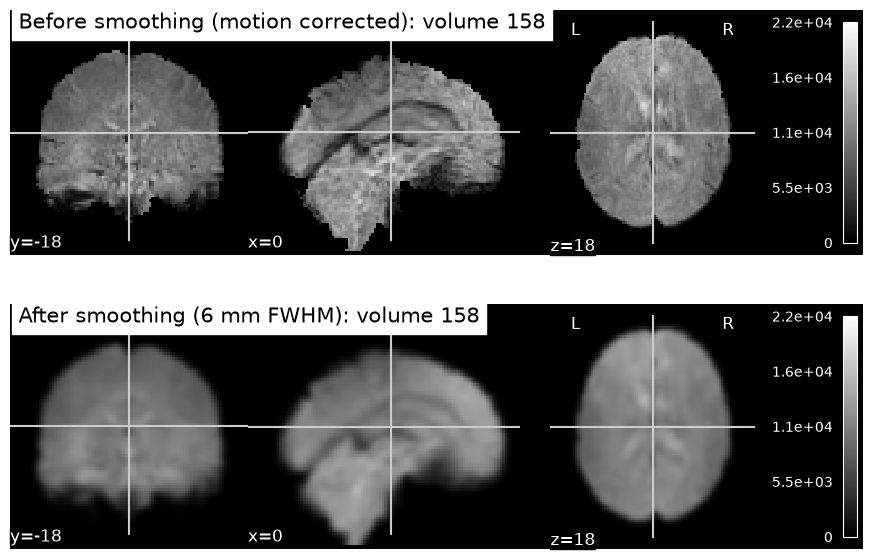

Compared volume index (0-based): 158
Slice coordinates (image world space): (np.float64(0.0), np.float64(-18.0), np.float64(18.0))


In [11]:
volume_index = n_volumes // 2
before_smoothing = image.index_img(moco_img, volume_index)
after_smoothing = image.index_img(smoothed_img, volume_index)
before_data = before_smoothing.get_fdata()
after_data = after_smoothing.get_fdata()
assert np.all(np.isfinite(before_data)) and np.all(np.isfinite(after_data)), 'Invalid comparison volume.'
vmin = min(before_data.min(), after_data.min())
vmax = max(before_data.max(), after_data.max())

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
for ax, volume, title in zip(
    axes, [before_smoothing, after_smoothing],
    ['Before smoothing (motion corrected)', f'After smoothing ({FWHM_MM:g} mm FWHM)']
):
    plotting.plot_epi(volume, axes=ax, display_mode='ortho', cut_coords=cut_coords,
                      cmap='gray', vmin=vmin, vmax=vmax, colorbar=True,
                      title=f'{title}: volume {volume_index}')
fig.savefig(OUTPUT_DIR / 'smoothing_comparison.png', dpi=200, bbox_inches='tight')
plt.show()
print('Compared volume index (0-based):', volume_index)
print('Slice coordinates (image world space):', cut_coords)

**Results.** Gaussian spatial smoothing was applied to the motion-corrected functional images using a kernel with a full width at half maximum (FWHM) of 6 mm, corresponding to approximately three voxels at the 2 mm isotropic resolution.

Visual comparison before and after smoothing shows a more homogeneous image, with reduced fine-scale intensity variations. As expected, anatomical boundaries and small structures appear less sharply defined after smoothing.

Spatial smoothing can improve the sensitivity of subsequent statistical analyses by reducing high-frequency spatial noise and increasing the spatial coherence of the signal. However, this comes at the cost of spatial resolution, as signals from neighboring voxels are mixed.

The 6 mm FWHM kernel represents a reasonable compromise for task-based fMRI analysis at this resolution. Its effect on the detection of task-related activations will be evaluated during the GLM analysis.

## 3. Functional–Anatomical Alignment (2c)

After motion correction and Gaussian smoothing, we assess the spatial alignment between the functional MRI and the T1-weighted anatomical image.

Functional images provide information about brain activity over time, while the anatomical MRI offers higher spatial resolution and clearer structural details. Aligning these images allows us to relate functional signals to anatomical brain regions.

Since the HCP dataset may already contain spatially preprocessed images, we first inspect their dimensions, voxel resolutions, orientations, and coordinate systems before deciding whether an additional registration is necessary.

We then compare the functional and anatomical images visually to evaluate their spatial correspondence.

The goal is to verify that the functional data can be reliably related to the anatomical reference for subsequent GLM analysis.

### 3.1 Alignment Input Files

Before evaluating the functional–anatomical alignment, we identify the images generated during structural and functional preprocessing.

From the structural preprocessing notebook, we use the T1-weighted anatomical images registered to MNI152 space with FLIRT and ANTs SyN.

From the functional preprocessing steps, we use the motion-corrected and Gaussian-smoothed fMRI images.

We also load the MNI152 2 mm brain template as a common spatial reference. The input files are checked before proceeding to ensure that all required images are available.

No additional spatial transformation is applied at this stage.

In [12]:
# Structural preprocessing outputs (notebook 01)
REGISTRATION_DIR = PROJECT_ROOT / "outputs" / "registration_mni"

anat_syn_path = REGISTRATION_DIR / "T1w_brain_MNI_SyN.nii.gz"
anat_flirt_path = REGISTRATION_DIR / "T1w_brain_MNI.nii.gz"

# MNI152 reference at functional resolution (2 mm)
mni_2mm_path = (
    Path(os.environ["FSLDIR"])
    / "data"
    / "standard"
    / "MNI152_T1_2mm_brain.nii.gz"
)

# Verify that all required images exist
alignment_inputs = {
    "T1w registered with ANTs SyN": anat_syn_path,
    "T1w registered with FLIRT": anat_flirt_path,
    "Motion-corrected fMRI": moco_fmri_path,
    "Smoothed fMRI": smoothed_fmri_path,
    "MNI152 2 mm template": mni_2mm_path
}

print("Functional–Anatomical Alignment — Input Files")
print("-" * 55)

for name, path in alignment_inputs.items():
    if not path.is_file():
        raise FileNotFoundError(f"Missing input: {path}")

    print(f"[OK] {name}: {path.name}")

Functional–Anatomical Alignment — Input Files
-------------------------------------------------------
[OK] T1w registered with ANTs SyN: T1w_brain_MNI_SyN.nii.gz
[OK] T1w registered with FLIRT: T1w_brain_MNI.nii.gz
[OK] Motion-corrected fMRI: tfMRI_LANGUAGE_LR_mcf.nii.gz
[OK] Smoothed fMRI: tfMRI_LANGUAGE_LR_mcf_smooth.nii.gz
[OK] MNI152 2 mm template: MNI152_T1_2mm_brain.nii.gz


### 3.2 Spatial Information of the Images

Following Lab 3, we first compare the spatial properties of the motion-corrected fMRI, the MNI152 template, and the T1-weighted anatomical image registered to MNI space.

We examine their dimensions, voxel resolutions, orientations, and affine matrices. The affine matrix maps voxel indices to physical coordinates in millimetres, allowing us to determine whether images are represented on the same spatial grid.

The functional images have a lower spatial resolution than the anatomical MRI. However, different voxel resolutions do not necessarily indicate misalignment, since images can share a common coordinate system while being sampled on different grids.

In particular, we check whether the fMRI is already represented on the MNI152 2 mm grid, which would help determine whether an additional spatial normalization step is required.

In [13]:
# Load functional and anatomical images
moco_img = nib.load(str(moco_fmri_path))
mni_2mm_img = nib.load(str(mni_2mm_path))
anat_syn_img = nib.load(str(anat_syn_path))
anat_flirt_img = nib.load(str(anat_flirt_path))

# Compare spatial properties
for name, img in [
    ("fMRI (motion-corrected)", moco_img),
    ("MNI152 2 mm template", mni_2mm_img),
    ("T1w in MNI space (SyN)", anat_syn_img),
    ("T1w in MNI space (FLIRT)", anat_flirt_img)
]:
    print(f"\n{name}")
    print("  Dimensions:", img.shape)
    print("  Voxel size (mm):", img.header.get_zooms()[:3])
    print("  Orientation:", nib.aff2axcodes(img.affine))
    print("  Affine:\n", np.round(img.affine, 2))

# Check whether the fMRI is on the MNI152 2 mm grid
same_grid = (
    moco_img.shape[:3] == mni_2mm_img.shape
    and np.allclose(moco_img.affine, mni_2mm_img.affine)
)

print("\nfMRI on the MNI152 2 mm grid:", same_grid)


fMRI (motion-corrected)
  Dimensions: (91, 109, 91, 316)
  Voxel size (mm): (np.float32(2.0), np.float32(2.0), np.float32(2.0))
  Orientation: ('L', 'A', 'S')
  Affine:
 [[  -2.    0.    0.   90.]
 [   0.    2.    0. -126.]
 [   0.    0.    2.  -72.]
 [   0.    0.    0.    1.]]

MNI152 2 mm template
  Dimensions: (91, 109, 91)
  Voxel size (mm): (np.float32(2.0), np.float32(2.0), np.float32(2.0))
  Orientation: ('L', 'A', 'S')
  Affine:
 [[  -2.    0.    0.   90.]
 [   0.    2.    0. -126.]
 [   0.    0.    2.  -72.]
 [   0.    0.    0.    1.]]

T1w in MNI space (SyN)
  Dimensions: (182, 218, 182)
  Voxel size (mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0))
  Orientation: ('L', 'A', 'S')
  Affine:
 [[  -1.   -0.    0.   90.]
 [  -0.    1.   -0. -126.]
 [   0.    0.    1.  -72.]
 [   0.    0.    0.    1.]]

T1w in MNI space (FLIRT)
  Dimensions: (182, 218, 182)
  Voxel size (mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0))
  Orientation: ('L', 'A', 'S')
  Affine:
 [[ 

### 3.3 Selection of a Functional Volume

To assess functional–anatomical alignment, we select one representative volume from the motion-corrected fMRI time series.

Since the functional image is four-dimensional, a single three-dimensional volume is extracted for visualization and comparison with the anatomical T1-weighted images.

We use the middle volume of the run and compare it with the anatomical images registered to MNI space using FLIRT and ANTs SyN.

The motion-corrected image is used instead of the smoothed image because it preserves sharper anatomical boundaries, making the visual alignment assessment easier.

In [14]:
# Select the middle functional volume for alignment inspection
alignment_volume_index = moco_img.shape[3] // 2

functional_volume = image.index_img(
    str(moco_fmri_path),
    alignment_volume_index
)

print("Selected functional volume:", alignment_volume_index)
print("Volume dimensions:", functional_volume.shape)
print("Voxel size (mm):", functional_volume.header.get_zooms()[:3])
print("Orientation:", nib.aff2axcodes(functional_volume.affine))

Selected functional volume: 158
Volume dimensions: (91, 109, 91)
Voxel size (mm): (np.float32(2.0), np.float32(2.0), np.float32(2.0))
Orientation: ('L', 'A', 'S')


### 3.4 Comparison of FLIRT and ANTs SyN Alignment

To further evaluate functional–anatomical alignment, we compare the anatomical T1-weighted images registered to MNI space using FLIRT and ANTs SyN.

Both anatomical images are overlaid on the same motion-corrected functional volume, using identical slice coordinates. The anatomical boundaries are displayed in red to facilitate visual comparison.

FLIRT uses a global affine transformation, while ANTs SyN additionally models nonlinear anatomical deformations. Comparing their overlays helps us assess which registered anatomical image provides better correspondence with the functional data.

We focus on the overall brain boundaries, ventricles, cerebellum, and brainstem. Differences in MRI contrast and possible EPI distortions must also be considered when interpreting the overlays.

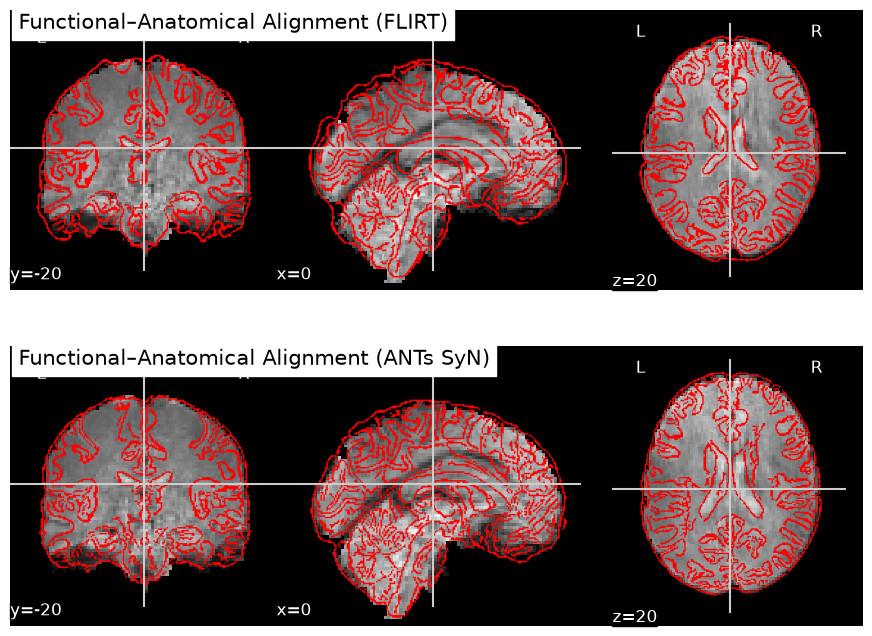

In [15]:
# Compare FLIRT and ANTs SyN anatomical alignment with fMRI
fig, axes = plt.subplots(2, 1, figsize=(11, 8))

registrations = [
    (anat_flirt_path, "Functional–Anatomical Alignment (FLIRT)"),
    (anat_syn_path, "Functional–Anatomical Alignment (ANTs SyN)")
]

for ax, (anat_path, title) in zip(axes, registrations):

    display = plotting.plot_epi(
        functional_volume,
        title=title,
        display_mode="ortho",
        cut_coords=(0, -20, 20),
        cmap="gray",
        axes=ax
    )

    display.add_edges(
        str(anat_path),
        color="red"
    )

fig.savefig(OUTPUT_DIR / 'alignment_flirt_vs_syn.png', dpi=200, bbox_inches='tight')
plt.show()

### 3.4.1 Visual Comparison Results

Both registered T1w images show a good global correspondence with the functional volume: the outer brain boundary, the interhemispheric fissure and the cerebellum are approximately aligned in the three views.

The two registrations differ in the internal structures. With FLIRT, the edges of the lateral ventricles and of the corpus callosum are visibly shifted with respect to the dark ventricles of the EPI, particularly in the axial and sagittal views. With ANTs SyN, these edges follow the ventricles and the corpus callosum of the EPI closely. This is expected: the HCP pipeline registered the functional data to MNI space with a non-linear warp, which an affine transformation cannot reproduce.

Small mismatches remain at the cortical boundary and in inferior regions, due to the lower resolution of the EPI (2 mm) and to susceptibility-related signal dropout. A quantitative overlap measure is used below as an additional check.

### 3.5 Quantitative Check of the Alignment

To complement the visual inspection, we compare the brain masks of the functional and anatomical images using the Dice coefficient.

The Dice coefficient is defined as:

$$
\mathrm{Dice}(A,B) = \frac{2\,|A \cap B|}{|A| + |B|}
$$

where \(A\) and \(B\) represent two binary brain masks, and
\(|A \cap B|\) is the number of voxels shared by both masks.

We estimate a brain mask from the selected functional volume and compare it with masks derived from the FLIRT-registered T1w, ANTs SyN-registered T1w, and MNI152 template.

The anatomical masks are resampled onto the functional image grid before comparison.

This provides an additional quantitative quality-control measure, although Dice depends on how the masks are defined and does not directly measure the accuracy of internal anatomical alignment.

In [16]:
from nilearn.masking import compute_epi_mask

# Dice coefficient between two binary masks
def dice(mask_a, mask_b):
    intersection = np.logical_and(mask_a, mask_b).sum()
    return 2 * intersection / (mask_a.sum() + mask_b.sum())


# Estimate the functional brain mask
fmri_mask = compute_epi_mask(functional_volume).get_fdata() > 0

# Anatomical images to compare
anatomical_masks = {
    "T1w in MNI (SyN)": anat_syn_path,
    "T1w in MNI (FLIRT)": anat_flirt_path,
    "MNI152 2 mm template": mni_2mm_path
}

for name, path in anatomical_masks.items():

    # Ignore near-zero intensities outside the anatomical brain
    brain = image.math_img(
        "img > 0.01 * np.max(img)",
        img=str(path)
    )

    # Resample anatomical mask onto the functional grid
    mask = image.resample_to_img(
        brain,
        functional_volume,
        interpolation="nearest"
    ).get_fdata() > 0

    print(
        f"Dice (fMRI brain mask vs {name}): "
        f"{dice(fmri_mask, mask):.3f}"
    )

Dice (fMRI brain mask vs T1w in MNI (SyN)): 0.945
Dice (fMRI brain mask vs T1w in MNI (FLIRT)): 0.936
Dice (fMRI brain mask vs MNI152 2 mm template): 0.956


### 3.5.1 Quantitative Alignment Results

The Dice coefficients indicate high global brain-mask overlap between the functional MRI and the anatomical images in MNI space.

The Dice coefficient was **0.945 for ANTs SyN**, **0.936 for FLIRT**, and **0.956 for the MNI152 template**.

ANTs SyN achieved a slightly higher overlap than FLIRT (difference of 0.009), while the MNI152 template showed the highest overlap.

These results are consistent with the visual alignment assessment. However, Dice coefficients depend on the estimated masks and their intensity thresholds, and do not measure the accuracy of internal anatomical structures.

The highest overlap is obtained with the MNI152 template itself. This supports the conclusion that the supplied fMRI has already been normalised to this template by the HCP pipeline: our registered T1w images are only approximations of the template, and the non-linear one (SyN) is the closest of the two.

### 3.6 Interactive Inspection with FSLeyes

As in Lab 3, we also load the anatomical image and the motion-corrected functional run in FSLeyes.

By adjusting the opacity of the fMRI overlay and navigating through different anatomical slices and functional volumes, we can assess the alignment throughout the brain.

The ANTs SyN-registered T1-weighted image is used as the anatomical reference, while the motion-corrected fMRI is displayed as a semi-transparent overlay.

This interactive inspection complements the Nilearn visualizations and Dice coefficient measurements.

In [17]:
if OPEN_FSLEYES:
    subprocess.Popen([
        "fsleyes",
        str(anat_syn_path),
        str(moco_fmri_path), "--cmap", "hot", "--alpha", "50"
    ])

### 3.7 Alignment Results

The visual and quantitative checks indicate good overall alignment between the motion-corrected functional MRI and the anatomical T1-weighted images registered to MNI space.

**Visual alignment.**

- **Orientation:** The functional image, anatomical images, and MNI152 template share the same LAS orientation. Their spatial coordinates are consistent across the three anatomical views.
- **Ventricles:** With the SyN-registered T1w, the edges of the lateral ventricles and of the corpus callosum follow the corresponding structures of the EPI closely; with FLIRT, they are visibly shifted (section 3.4.1).
- **Brain boundaries:** The outer brain boundaries and interhemispheric fissure show reasonable correspondence between the functional and anatomical images.

**Quantitative alignment.**

The functional image has the same spatial grid as the MNI152 2 mm template (91 × 109 × 91 voxels, 2 mm isotropic resolution).

The Dice coefficients between the functional brain mask and the anatomical masks were:

- **ANTs SyN:** 0.945
- **FLIRT:** 0.936
- **MNI152 template:** 0.956

Both anatomical registrations show high brain-mask overlap with the fMRI, with a slightly higher value for ANTs SyN, and the highest overlap is obtained with the MNI152 template itself, to which the HCP pipeline normalised the functional data. Since Dice only measures the overlap of the outer brain masks, the clearer difference between the two registrations is seen in the internal structures (ventricles, corpus callosum), which are better matched with SyN. We therefore use the SyN-registered T1w as the anatomical reference.

**Remaining differences.**

Some local mismatches remain, as expected:

- **Spatial resolution:** The functional EPI images have a lower resolution (2 mm) than the registered anatomical T1w images (1 mm), making fine cortical boundaries less clearly defined.
- **EPI susceptibility effects:** Signal dropout and geometric distortions may affect regions near air–tissue interfaces, particularly the orbitofrontal and inferior temporal areas. These effects can contribute to differences between functional and anatomical images.

**Which functional preprocessing step can be avoided?**

Following the alignment checks, an additional functional-to-anatomical registration and spatial normalization to MNI space are not required for this dataset.

The supplied functional images are already sampled on the MNI152 2 mm grid, and the visual comparisons show reasonable correspondence with the registered anatomical images. Performing another registration without evidence of a remaining alignment problem could introduce unnecessary interpolation.

Therefore, we retain the functional images in their existing MNI space for subsequent GLM analysis, while preserving the motion-correction parameters for possible nuisance regression.

### 3.8 Preprocessing Steps Not Applied

Some functional preprocessing steps seen in Labs 3 and 4 were not applied, for the following reasons:

- **Removal of initial volumes (Lab 3):** all volumes are kept to preserve the timing of the task events; the two non-steady-state volumes are censored in the GLM with spike regressors.
- **Slice-timing correction (Lab 4):** the HCP data are acquired with a multiband sequence and a short TR (0.72 s), so the timing differences between slices are small compared with the slow haemodynamic response and the ~30 s task blocks.
- **Field-map unwarping (Lab 4):** no field maps are provided in our dataset, and the HCP minimal preprocessing pipeline already corrects EPI distortions.
- **Coregistration and normalisation of the fMRI (Labs 3–4):** the run is already in MNI space (section 3), so these steps would only add an unnecessary interpolation.

## 4. Final Outputs and Verification

The functional preprocessing pipeline produced the motion-corrected and Gaussian-smoothed fMRI images, together with the motion parameters and quality-control results.

The main outputs are saved in `outputs/functional/`:

- `tfMRI_LANGUAGE_LR_mcf.nii.gz`: motion-corrected functional run.
- `tfMRI_LANGUAGE_LR_mcf.par`: six motion parameters estimated by MCFLIRT.
- `tfMRI_LANGUAGE_LR_mcf_smooth.nii.gz`: motion-corrected and Gaussian-smoothed functional run.
- `framewise_displacement.csv`: framewise displacement values and motion quality-control flags.

Additional figures document the mean signal intensity, estimated motion parameters, framewise displacement, motion correction, and Gaussian smoothing.

Functional–anatomical alignment was evaluated using the MNI-registered T1-weighted images from the structural preprocessing notebook. Visual inspection and Dice coefficients indicated good overall spatial correspondence.

The supplied functional data already matched the MNI152 2 mm reference grid, so no additional spatial normalization was applied.

All 316 functional volumes were preserved. The final smoothed image and motion parameters are available for the subsequent GLM analysis, where task-related regressors, nuisance variables, and statistical contrasts will be defined.

In [18]:
# Final functional preprocessing output verification

expected_outputs = {
    "Motion-corrected fMRI": moco_fmri_path,
    "MCFLIRT motion parameters": motion_par_path,
    "Gaussian-smoothed fMRI": smoothed_fmri_path,
    "Framewise displacement CSV": OUTPUT_DIR / "framewise_displacement.csv",
    "Mean intensity figure": OUTPUT_DIR / "mean_intensity.png",
    "Motion parameters figure": OUTPUT_DIR / "motion_parameters.png",
    "Framewise displacement figure": OUTPUT_DIR / "framewise_displacement.png",
    "Motion correction comparison": OUTPUT_DIR / "motion_correction_comparison.png",
    "Smoothing comparison": OUTPUT_DIR / "smoothing_comparison.png",
    "Anatomical T1w (ANTs SyN)": anat_syn_path,
    "Anatomical T1w (FLIRT)": anat_flirt_path,
    "MNI152 2 mm template": mni_2mm_path,
    "Alignment figure": OUTPUT_DIR / "alignment_flirt_vs_syn.png",
}

print("Functional Preprocessing — Final Outputs")
print("-" * 60)

for name, path in expected_outputs.items():
    if not path.is_file():
        raise FileNotFoundError(f"Missing output: {path}")

    print(f"[OK] {name}")
    print(f"     {path.relative_to(PROJECT_ROOT) if path.is_relative_to(PROJECT_ROOT) else path}")

# Verify functional image geometry
raw_check = nib.load(str(raw_fmri_path))
moco_check = nib.load(str(moco_fmri_path))
smooth_check = nib.load(str(smoothed_fmri_path))
mni_check = nib.load(str(mni_2mm_path))

assert raw_check.shape == moco_check.shape == smooth_check.shape
assert np.allclose(raw_check.affine, moco_check.affine)
assert np.allclose(moco_check.affine, smooth_check.affine)

# Verify matching MNI spatial grid
assert moco_check.shape[:3] == mni_check.shape
assert np.allclose(moco_check.affine, mni_check.affine)

# Verify motion parameters
motion_check = np.loadtxt(motion_par_path)
assert motion_check.shape == (raw_check.shape[3], 6)
assert np.all(np.isfinite(motion_check))

# Verify FD measurements
fd_check = pd.read_csv(OUTPUT_DIR / "framewise_displacement.csv")
assert len(fd_check) == raw_check.shape[3] - 1
assert np.all(np.isfinite(fd_check["fd_mm"]))
assert (fd_check["fd_mm"] >= 0).all()

print("\nFunctional volumes:", smooth_check.shape[3])
print("Volumes removed: 0")
print("MNI152 spatial grid: verified")
print("Motion parameters: verified")
print("Framewise displacement: verified")
print("\nAll functional preprocessing outputs verified.")

Functional Preprocessing — Final Outputs
------------------------------------------------------------
[OK] Motion-corrected fMRI
     outputs/functional/tfMRI_LANGUAGE_LR_mcf.nii.gz
[OK] MCFLIRT motion parameters
     outputs/functional/tfMRI_LANGUAGE_LR_mcf.par
[OK] Gaussian-smoothed fMRI
     outputs/functional/tfMRI_LANGUAGE_LR_mcf_smooth.nii.gz
[OK] Framewise displacement CSV
     outputs/functional/framewise_displacement.csv
[OK] Mean intensity figure
     outputs/functional/mean_intensity.png
[OK] Motion parameters figure
     outputs/functional/motion_parameters.png
[OK] Framewise displacement figure
     outputs/functional/framewise_displacement.png
[OK] Motion correction comparison
     outputs/functional/motion_correction_comparison.png
[OK] Smoothing comparison
     outputs/functional/smoothing_comparison.png
[OK] Anatomical T1w (ANTs SyN)
     outputs/registration_mni/T1w_brain_MNI_SyN.nii.gz
[OK] Anatomical T1w (FLIRT)
     outputs/registration_mni/T1w_brain_MNI.nii.gz
[OK